In [2]:
import networkx as nx
import matplotlib.pyplot as plt

In [3]:
tau = {
    ("VO","boire","vivant"),
    ("VO","emp","VE"),
    ("VO","vider","VV"),
    ("VE","vider","VV"),
    ("VE","boire","mort"),
    ("VE","antidote","VA"),
    ("VA","boire","vivant"),
    ("VV","$\\varnothing$","mort"),
    ("vivant","$\\varnothing$","vivant"),
    ("mort","$\\varnothing$","mort")
}
expert = {
    "VO": {"boire":1,"vider":0.5,"emp":0.1},
    "VE": {"antidote":1,"boire":0.1,"vider":0.5},
    "VV": {"$\\varnothing$":0.5},
    "VA": {"boire":1},
    "mort" : {"$\\varnothing$":1},
    "vivant":{"$\\varnothing$":1}
}
scenarios = {
    "sigma_1": ["VO","emp","VE","boire","mort"],
    "sigma_2": ["VO","boire","vivant"],
    "sigma_3": ["VO","vider","VV","$\\varnothing$","mort"],
    "sigma_4": ["VO","emp","VE","vider","VV","$\\varnothing$","mort"],
    "sigma_5": ["VO", "emp","VE","antidote","VA","boire","vivant"]
}

In [109]:
P_graph = nx.DiGraph()
# #ajout nodes et edges
# for (s1,a,s2) in tau:
#     P_graph.add_edge(s1, s2, label=a)

# #ajout des poids
# for (s1,a,s2) in tau:
#     P_graph[s1][s2]['weight'] = expert[s1][a]

P_graph.add_edge("VO", "vivant", label="boire", weight=1)
P_graph.add_edge("VO", "VE", label="emp", weight=0.1)
P_graph.add_edge("VO", "VV", label="vider", weight=0.5)
P_graph.add_edge("VE", "VV", label="vider", weight=0.5)
P_graph.add_edge("VE", "mort", label="boire", weight=0.1)
P_graph.add_edge("VE", "VA", label="antidote", weight=1)
P_graph.add_edge("VA", "vivant", label="boire", weight=1)
P_graph.add_edge("VV", "mort", label="$\\varnothing$", weight=0.5)
P_graph.add_edge("vivant", "vivant", label="$\\varnothing$", weight=1)
P_graph.add_edge("mort", "mort", label="$\\varnothing$", weight=1)

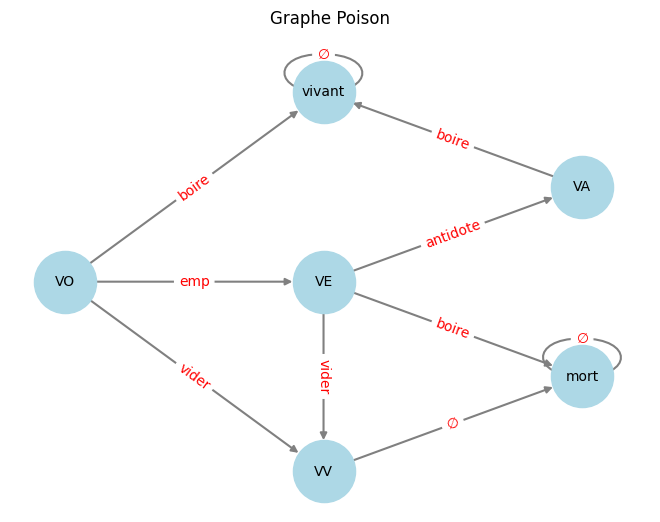

In [110]:
pos = {"VO":(0,2),"vivant":(1,4),"VE":(1,2),"VV":(1,0),"VA":(2,3),"mort":(2,1)}
edge_labels = nx.get_edge_attributes(P_graph, 'label')
options = {
    "node_color": 'lightblue',
    "node_size": 2000,
    "font_size": 10,
    "edge_color": 'gray',
    "width": 1.5,
}
nx.draw(P_graph, pos, with_labels=True, **options)
nx.draw_networkx_edge_labels(P_graph, pos, edge_labels=edge_labels, font_color='red')

plt.title("Graphe Poison")
plt.show()

In [111]:
def complete_policy(pi, graph):
    #si une politique est definie partiellement on la complete, lorsqu'un unique arc sortant est disponible on
    #selectionne cet event, si plusieurs choix sont possibles on selectionne l'action la plus probable selon l'expert
    res_pi = pi.copy()
    for node in graph.nodes():
        if node not in res_pi:
            out_edges = list(graph.out_edges(node, data=True))
            if len(out_edges)==1:
                res_pi[node] = out_edges[0][2]['label']
            elif len(out_edges)>1:
                best_action= max(out_edges,key=lambda edge:edge[2]['weight'])
                res_pi[node]= best_action[2]['label']
    return res_pi

In [112]:
pi1 = {'VO': 'emp', 'VE': 'boire'}
pi2 = {'VO': 'boire'}   
pi3 = {'VO': 'vider', 'VV': '$\\varnothing$'}
pi4 = {'VO': 'emp', 'VE': 'vider', 'VV': '$\\varnothing$'}
pi5 = {'VO': 'emp', 'VE': 'antidote', 'VA': 'boire'}
policies = {"pi1": complete_policy(pi1, P_graph), "pi2": complete_policy(pi2, P_graph), "pi3": complete_policy(pi3, P_graph), "pi4": complete_policy(pi4, P_graph), "pi5": complete_policy(pi5, P_graph)}



In [113]:
def is_terminal_state(state, graph):
    #les états terminaux sont ceux qui ont pour unique successeur eux memes
    out_edges = list(graph.out_edges(state))
    return len(out_edges)==1 and out_edges[0][1]==state
def next_state(state, action, graph):
    for _, succ, data in graph.out_edges(state, data=True):
        if data['label'] == action:
            return succ
    raise ValueError(f"{state}: action {action} non valide pour cet état")

In [114]:
def extract_sigma(pi, graph,S0):
    #extrait le chemin emprunté par une politique pi à partir d'un état initial S0 dans le graphe graph
    path = [S0]
    current_state = S0
    terminals = [node for node in graph.nodes() if is_terminal_state(node, graph)]
    while current_state not in terminals:
        action = pi[current_state]
        path.append(action)
        next_s = next_state(current_state, action, graph)
        path.append(next_s)
        current_state = next_s
    return path

def extract_sigma_state(path):
    #extrait la séquence d'etats d'un chemin
    return path[::2]
def extract_sigma_event(path):
    #extrait la séquence d'événements d'un chemin
    return path[1::2]

In [126]:
def get_edge(graph,node1,node2):
    #renvoie l'arc entre node1 et node2 dans graph, si plusieurs arcs existent on utilise l'heuristique pour choisir
    print(node1, node2)
    edge = list(graph.get_edge_data(node1, node2).values())
    if not edge:
        raise ValueError(f"pas d'arc entre {node1} et {node2}")
    return edge
    

In [127]:
def astar_trace(graph,start,end):
    path = nx.astar_path(graph, start, end, weight='weight')
    res = []
    for i in range(len(path)-1):
        edge = get_edge(graph,path[i],path[i+1])
        res.append(path[i])
        res.append(edge)
    res.append(path[-1])
    return res



politique optimale sans plannification
$    \begin{equation}
        \forall S\in S \quad \pi^{opt}_\tau(S) = \underset{E}{argmax} (expert\_{judge}_\tau(S))
    \end{equation}$

In [128]:
def optimal_policy_no_plan(graph):
    policy = {}
    for s in graph.nodes():
        edges = list(graph.out_edges(s, data=True))
        if not edges:
            continue
        best_edge = max(edges, key=lambda edge: edge[2]['weight'])
        policy[s] = best_edge[2]['label']
    return policy
        

In [129]:
optimal_policy_no_plan(P_graph)

{'VO': 'boire',
 'vivant': '$\\varnothing$',
 'VE': 'antidote',
 'VV': '$\\varnothing$',
 'mort': '$\\varnothing$',
 'VA': 'boire'}

politique optimale avec une plannification à un horizon n
$    \begin{equation}
        \forall S \in S, \quad \pi^{opt}_\tau(S) = \underset{\pi \in \Pi_\tau}{\argmax} \; 
        Agg_{k=1}^{n-1} \left( expert\_judge_\tau\!\left(S^{(k)}\right)\!\left[\pi^{(k+1)}(S)\right] \right)
    \end{equation}$

In [130]:
import numpy as np
def optimal_policy_plan_n(graph, n = 1, agg= lambda liste: np.mean(liste)):
    policy = {}
    for s in graph.nodes():
        #recupere tous les chemins depuis s de longueur n
        



_IncompleteInputError: incomplete input (4063561850.py, line 7)

In [137]:
def compute_score(path,graph, agg):
    scores = []
    for i in range(0, len(path)-2, 2):
        edge = get_edge(graph,path[i],path[i+2])
        print(edge)
        scores.append(edge[1])
    return agg(scores)

paths = list(nx.all_simple_paths(P_graph, source="VO", target="mort", cutoff=5))
print(paths)
print(paths[0], compute_score(paths[0], P_graph, np.mean))

[['VO', 'VE', 'VV', 'mort'], ['VO', 'VE', 'mort'], ['VO', 'VV', 'mort']]
VO VV
['vider', 0.5]
['VO', 'VE', 'VV', 'mort'] 0.5


In [67]:
for p in path:    print(p)

['VO', 'VV', 'mort']
['VO', 'VE', 'mort']
